## Colab dependency setup

In [1]:
# Install the notebook extras without replacing Colab's GPU frameworks.
import importlib.util
import subprocess
import sys

expected_network = {'yfinance': '0.2.66', 'curl_cffi': '0.13.0'}
stale_network = [name for name, expected in expected_network.items()
    if name in sys.modules and getattr(sys.modules[name], '__version__', None) != expected]
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'yfinance==0.2.66', 'curl_cffi==0.13.0', 'mplfinance==0.12.10b0'])
if stale_network:
    raise RuntimeError('Updated network packages are installed, but older copies are still loaded. '
        'Restart the Colab session/runtime, then select Run all again. Do not just rerun this cell.')
# The PyTorch backend uses numpy and torch, which are already in Colab.
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    '--no-deps', 'nbeats-pytorch==1.8.0'])
base = {'numpy':'numpy', 'pandas':'pandas', 'matplotlib':'matplotlib',
        'sklearn':'scikit-learn', 'tensorflow':'tensorflow',
        'torch':'torch', 'xgboost':'xgboost'}
missing = [package for module, package in base.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Dependencies ready. Continue with the next cells.')

Dependencies ready. Continue with the next cells.


## <u>Import Statements</u>

In [2]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import json, platform, random, time, warnings
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
# Load curl_cffi before TensorFlow loads its native libraries.
from curl_cffi import requests as curl_requests
import curl_cffi
import yfinance as yf
import tensorflow as tf
from tensorflow import keras

# Configure this before the first model uses the GPU. PyTorch also needs memory.
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        warnings.warn(f'GPU already initialized: {exc}')
import torch
from torch.utils.data import DataLoader, TensorDataset
import xgboost as xgb
import mplfinance as mpf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from nbeats_pytorch.model import NBeatsNet

random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
print('Python:', platform.python_version())
print('TensorFlow:', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))
print('PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
print('yfinance:', yf.__version__, '| pandas:', pd.__version__)
print('curl_cffi:', curl_cffi.__version__, '| Yahoo browser profile: chrome124')

Python: 3.13.18
TensorFlow: 2.21.0 | GPUs: []
PyTorch: 2.14.1+cpu | CUDA: False
yfinance: 0.2.66 | pandas: 2.2.3
curl_cffi: 0.13.0 | Yahoo browser profile: chrome124


In [3]:
#@title Experiment settings
desired_company = "NVDA" #@param {type:"string"}
start_year = 2020 #@param {type:"integer"}
end_year = 2026 #@param {type:"integer"}
LOOKBACK = 30 #@param {type:"integer"}
TRAIN_FRACTION = 0.95 #@param {type:"number"}
LSTM_EPOCHS = 40 #@param {type:"integer"}
NBEATS_EPOCHS = 50 #@param {type:"integer"}
DOWNLOAD_ALL_TICKERS = False #@param {type:"boolean"}
PLOT_ALL_SECTORS = False #@param {type:"boolean"}
CSV_PATH = "" #@param {type:"string"}
# CSV_PATH is optional: upload a CSV in the Files sidebar and paste its path.
# Required CSV columns: Date,Ticker,Open,High,Low,Close,Volume.
OUTPUT_DIR = Path('/content/financial_forecasting_outputs') if Path('/content').exists() else Path('financial_forecasting_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
desired_company = desired_company.strip().upper()
if not desired_company:
    raise ValueError('Enter a stock ticker, for example NVDA or AAPL.')
if end_year <= start_year or not 3 <= end_year - start_year <= 10:
    raise ValueError('Choose end_year > start_year with a difference of 3–10 years.')
if not 0.5 <= TRAIN_FRACTION < 1:
    raise ValueError('TRAIN_FRACTION must be at least 0.5 and below 1.')
if LOOKBACK < 2 or LSTM_EPOCHS < 1 or NBEATS_EPOCHS < 1:
    raise ValueError('Use LOOKBACK >= 2 and positive epoch counts.')
print('Selected ticker:', desired_company, '| output folder:', OUTPUT_DIR)

Selected ticker: NVDA | output folder: /content/financial_forecasting_outputs


## <u>Loading Financial Data</u>
- Leverage the yfinance library, Yahoo Finance's public API, to fetch historical market data.

In [4]:
# Create a ticker list grouped by sector to download market data
tickers = [
    # Technology
    "AAPL",   # Apple
    "MSFT",   # Microsoft
    "GOOGL",  # Alphabet
    "AMZN",   # Amazon
    "META",   # Meta
    "NVDA",   # Nvidia
    "AMD",    # AMD
    "ORCL",   # Oracle
    "CRM",    # Salesforce
    "INTC",   # Intel
    "IBM",    # IBM

    # Finance
    "JPM",    # JPMorgan
    "BAC",    # Bank of America
    "GS",     # Goldman Sachs
    "MS",     # Morgan Stanley
    "V",      # Visa
    "MA",     # Mastercard
    "AXP",    # American Express
    "BLK",    # BlackRock

    # Healthcare
    "JNJ",    # Johnson & Johnson
    "PFE",    # Pfizer
    "MRK",    # Merck
    "UNH",    # UnitedHealth
    "ABBV",   # AbbVie
    "LLY",    # Eli Lilly

    # Energy
    "XOM",    # ExxonMobil
    "CVX",    # Chevron
    "COP",    # ConocoPhillips
    "SLB",    # Schlumberger

    # Consumer / Retail
    "WMT",    # Walmart
    "COST",   # Costco
    "TGT",    # Target
    "HD",     # Home Depot
    "MCD",    # McDonald's
    "SBUX",   # Starbucks
    "NKE",    # Nike
    "KO",     # Coca-Cola
    "PEP",    # PepsiCo

    # Industrials
    "CAT",    # Caterpillar
    "BA",     # Boeing
    "GE",     # General Electric
    "HON",    # Honeywell
    "UPS",    # UPS

    # Transportation / Automotive
    "TSLA",   # Tesla
    "F",      # Ford
    "GM",     # General Motors
    "DAL",    # Delta Airlines

    # Telecom / Media
    "DIS",    # Disney
    "NFLX",   # Netflix
    "T",      # AT&T
    "VZ",     # Verizon

    # ETFs / Market Benchmarks
    "SPY",    # S&P 500 ETF
    "QQQ",    # Nasdaq ETF
]

# Normalize both ticker-first and price-first yfinance MultiIndex layouts.
PRICE_COLS = ['Open', 'High', 'Low', 'Close', 'Volume']
def clean_market_frame(frame):
    required = ['Date', 'Ticker', *PRICE_COLS]
    absent = set(required) - set(frame.columns)
    if absent:
        raise ValueError(f'Market data is missing columns: {sorted(absent)}')
    result = frame[required].copy()
    result['Date'] = pd.to_datetime(result['Date'], utc=True, errors='coerce').dt.tz_convert(None).dt.normalize()
    result['Ticker'] = result['Ticker'].astype(str).str.strip().str.upper()
    for col in PRICE_COLS:
        result[col] = pd.to_numeric(result[col], errors='coerce')
    result = result.replace([np.inf, -np.inf], np.nan).dropna(subset=required)
    result = result[result['Close'] > 0]
    result = result.drop_duplicates(['Ticker', 'Date']).sort_values(['Ticker', 'Date']).reset_index(drop=True)
    return result

def normalize_download(raw, symbols):
    if raw is None or raw.empty:
        return pd.DataFrame(columns=['Date', 'Ticker', *PRICE_COLS])
    frames = []
    if isinstance(raw.columns, pd.MultiIndex):
        price_levels = [i for i in range(raw.columns.nlevels)
                        if set(PRICE_COLS).issubset(set(raw.columns.get_level_values(i)))]
        if len(price_levels) != 1 or raw.columns.nlevels != 2:
            raise ValueError('Unexpected Yahoo Finance column structure.')
        ticker_level = 1 - price_levels[0]
        available = set(raw.columns.get_level_values(ticker_level))
        for symbol in symbols:
            if symbol not in available:
                continue
            frame = raw.xs(symbol, axis=1, level=ticker_level).copy()
            frame.index.name = 'Date'
            frame = frame.reset_index()
            frame['Ticker'] = symbol
            frames.append(frame)
    else:
        if len(symbols) != 1:
            raise ValueError('Flat price columns require exactly one ticker.')
        frame = raw.copy()
        frame.index.name = 'Date'
        frame = frame.reset_index()
        frame['Ticker'] = symbols[0]
        frames.append(frame)
    if not frames:
        return pd.DataFrame(columns=['Date', 'Ticker', *PRICE_COLS])
    return clean_market_frame(pd.concat(frames, ignore_index=True))

required_tickers = sorted({desired_company, 'SPY', 'QQQ'})
requested_tickers = sorted(set(tickers + required_tickers)) if DOWNLOAD_ALL_TICKERS else required_tickers
# Daily forecasts use completed sessions only; today's incomplete daily bar is excluded.
download_start = f'{start_year}-01-01'
download_end = min(f'{end_year + 1}-01-01', datetime.now(timezone.utc).strftime('%Y-%m-%d'))
if download_start >= download_end:
    raise ValueError('The requested date range contains no completed history.')
if CSV_PATH.strip():
    data = clean_market_frame(pd.read_csv(CSV_PATH))
    data = data[(data['Date'] >= download_start) & (data['Date'] < download_end)].copy()
    data = data[data['Ticker'].isin(requested_tickers)].copy()
else:
    # Avoid the moving "chrome" alias (which can resolve to unsupported chrome152).
    # Validate the profile against the loaded native library before any HTTP request.
    from curl_cffi import Curl
    probe = Curl()
    try:
        profile_status = probe.impersonate('chrome124')
    finally:
        probe.close()
    if profile_status != 0:
        raise RuntimeError('The loaded curl library cannot use chrome124. Run the setup cell, '
            'restart the Colab session/runtime, and Run all again.')
    yahoo_session = curl_requests.Session(impersonate='chrome124')
    raw = yf.download(requested_tickers, start=download_start, end=download_end,
        group_by='ticker', auto_adjust=True, threads=False, progress=False,
        timeout=20, multi_level_index=True, session=yahoo_session)
    data = normalize_download(raw, requested_tickers)
    # Retry only failed symbols. A partial download must not silently omit a benchmark.
    for attempt in range(2):
        missing = sorted(set(requested_tickers) - set(data['Ticker']))
        if not missing:
            break
        time.sleep(2 * (attempt + 1))
        for symbol in missing:
            try:
                retry = yf.download(symbol, start=download_start, end=download_end,
                    auto_adjust=True, threads=False, progress=False, timeout=20,
                    multi_level_index=True, session=yahoo_session)
                data = pd.concat([data, normalize_download(retry, [symbol])], ignore_index=True)
            except Exception as exc:
                warnings.warn(f'{symbol} retry failed: {exc}')
    data = clean_market_frame(data)
missing_required = set(required_tickers) - set(data['Ticker'])
if missing_required:
    raise RuntimeError(f'No data for required tickers: {sorted(missing_required)}. '
        'Yahoo may be rate limiting Colab. Wait and rerun this cell, or upload '
        'a market_data.csv with the required columns and set CSV_PATH above.')
missing_optional = set(requested_tickers) - set(data['Ticker'])
if missing_optional:
    warnings.warn(f'Optional sector tickers unavailable: {sorted(missing_optional)}')
data.to_csv(OUTPUT_DIR / 'market_data.csv', index=False)
print(f'Downloaded {len(data):,} rows for {data.Ticker.nunique()} tickers.')
print('Observed dates:', data.Date.min().date(), 'through', data.Date.max().date())

Downloaded 5,196 rows for 3 tickers.
Observed dates: 2020-01-02 through 2026-11-20


In [5]:
assert not data.empty, 'Market dataset is empty.'
assert not data.duplicated(['Ticker', 'Date']).any()
assert set(required_tickers).issubset(set(data['Ticker']))
print(data.shape)
display(data.sample(min(10, len(data)), random_state=42))
data.info()
display(data.groupby('Ticker')['Date'].agg(['min', 'max', 'count']))

(5196, 7)


Price,Date,Ticker,Open,High,Low,Close,Volume
1334,2025-04-24,NVDA,103.219686,106.271986,102.850614,106.162262,220815000
79,2020-04-27,NVDA,7.329194,7.540630,7.304597,7.381122,479388000
3252,2026-01-21,QQQ,607.401349,618.314196,605.796828,614.188293,79837900
4378,2023-08-21,SPY,420.490931,422.951120,418.347892,422.211151,68719000
4296,2023-04-24,SPY,394.462165,395.496234,393.131317,395.074951,64332100
4625,2024-08-14,SPY,528.982464,531.038608,526.322223,529.859497,42446900
1813,2020-04-29,QQQ,208.344166,211.986984,207.332269,211.052185,48716400
2488,2023-01-03,QQQ,262.996320,264.464753,256.613542,258.914093,42335300
721,2022-11-10,NVDA,14.746910,15.716419,14.494817,15.693501,700819000
2111,2021-07-06,QQQ,348.295047,349.477812,345.609571,349.196655,38842400


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5196 entries, 0 to 5195
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    5196 non-null   datetime64[ns]
 1   Ticker  5196 non-null   object        
 2   Open    5196 non-null   float64       
 3   High    5196 non-null   float64       
 4   Low     5196 non-null   float64       
 5   Close   5196 non-null   float64       
 6   Volume  5196 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 284.3+ KB


,min,max,count
Ticker,,,
NVDA,2020-01-02,2026-11-20,1732
QQQ,2020-01-02,2026-11-20,1732
SPY,2020-01-02,2026-11-20,1732


## <u>Exploratory Data Analysis</u>
- Reviewed and visualized stock performance across three sectors: Information Technology, Financials, and Health Care
- Created candlestick charts to capture market data

In [6]:
# Candlestick chart visualization function
def plot_candlestick_with_volume(company: str, data: pd.DataFrame):
    c = data[data["Ticker"] == company].copy()
    if c.empty:
        print(f'Skipping unavailable chart: {company}')
        return
    c = c.sort_values('Date')
    c.set_index("Date", inplace = True)

    fig, axes = mpf.plot(c, type = "candle", style = "yahoo", ylabel = "Price (USD)", volume = True, figsize = (18, 9), returnfig = True, update_width_config = dict(candle_linewidth = 1, candle_width = 0.3))

    axes[0].set_title(f"{company}", fontsize = 20, fontweight = "bold", pad = 10)
    axes[0].set_ylabel("Price (USD)", fontsize = 12)
    axes[2].set_ylabel("Volume", fontsize = 12)
    axes[0].yaxis.set_label_position("left")
    axes[2].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:.1e}'))
    axes[0].yaxis.tick_left()

    dates = c.index
    six_month_periods = pd.date_range(start = f"{c.index[0].year}-01-01", end = c.index[-1], freq='6MS')

    tick_positions = [np.argmin(np.abs(dates - t)) for t in six_month_periods]
    tick_labels = [t.strftime('%b %Y') for t in six_month_periods]
    axes[0].set_xticks(tick_positions)
    axes[0].set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)

    plt.show()
    plt.close(fig)

---
#### **Information Technology Sector**
Selected the following companies for information technology stock visualizations:

- AAPL — Apple Inc.
- MSFT — Microsoft Corporation
- GOOGL — Alphabet Inc.
- AMZN — Amazon.com, Inc.
- META — Meta Platforms, Inc.
- NVDA — NVIDIA Corporation
- AMD — Advanced Micro Devices, Inc.
- ORCL — Oracle Corporation
- CRM — Salesforce, Inc.
- INTC — Intel Corporation
- IBM — International Business Machines Corporation

/usr/local/lib/python3.13/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


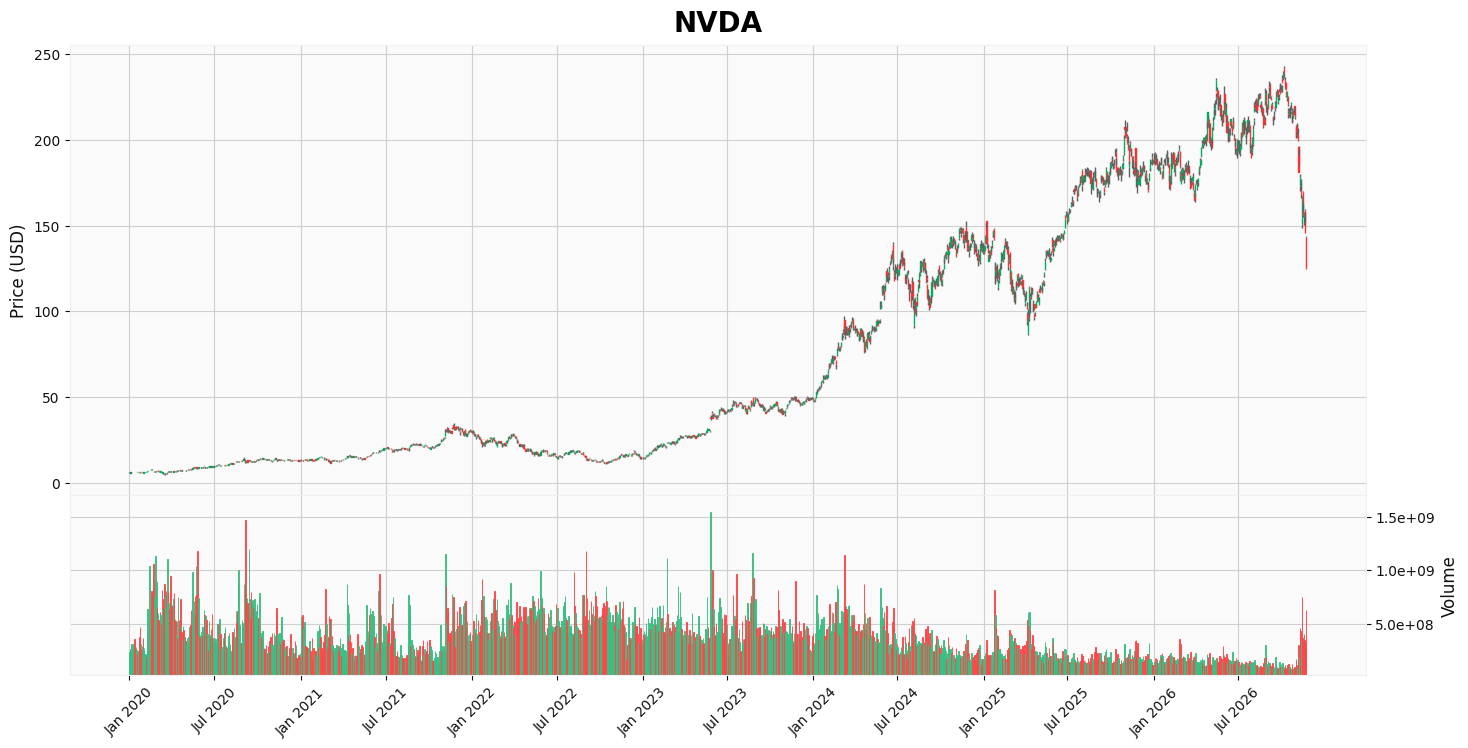

In [7]:
tech_companies = ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "NVDA", "AMD", "ORCL", "CRM", "INTC", "IBM"]

for comp in tech_companies:
    if PLOT_ALL_SECTORS or comp == desired_company:
        plot_candlestick_with_volume(comp, data)

---
#### **Financials Sector**
Selected the following companies for financial stock visualizations:

- JPM — JPMorgan Chase & Co.
- BAC — Bank of America Corporation
- GS — The Goldman Sachs Group, Inc.
- MS — Morgan Stanley
- V — Visa Inc.
- MA — Mastercard Incorporated
- AXP — American Express Company
- BLK — BlackRock, Inc.

In [8]:
finance_companies = ["JPM", "BAC", "GS", "MS", "V", "MA", "AXP", "BLK"]

for comp in finance_companies:
    if PLOT_ALL_SECTORS or comp == desired_company:
        plot_candlestick_with_volume(comp, data)

---
#### **Health Care Sector**
Selected the following companies for health care stock visualizations:

- JNJ — Johnson & Johnson
- PFE — Pfizer Inc.
- MRK — Merck & Co., Inc.
- UNH — UnitedHealth Group Incorporated
- ABBV — AbbVie Inc.
- LLY — Eli Lilly and Company

In [9]:
healthcare_companies = ["JNJ", "PFE", "MRK", "UNH", "ABBV", "LLY"]

for comp in healthcare_companies:
    if PLOT_ALL_SECTORS or comp == desired_company:
        plot_candlestick_with_volume(comp, data)

---
## <u>Modeling Setup</u>
- This section builds three stock forecasting pipelines using the same selected ticker, chronological train/test split, and one-step-ahead closing-price prediction task.
- The LSTM model uses multivariate 30-day sequences, XGBoost uses engineered tabular features to predict next-day return, and N-BEATS uses only historical closing prices as a univariate sequence.
- Each model is trained, evaluated with consistent performance metrics, and visualized against actual test-period prices.

---
##### **Company Selection**

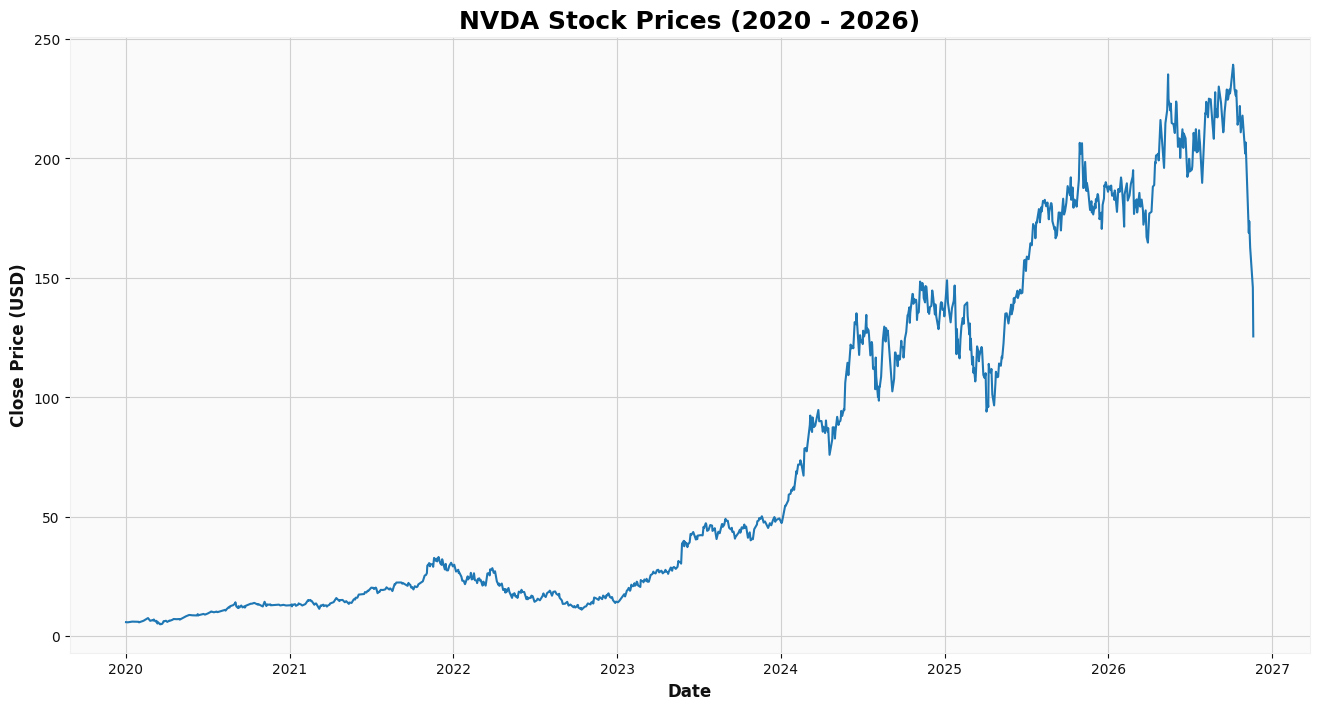

In [10]:
# Company and date range are configured in the Experiment settings cell.
prediction_data = data[data["Ticker"] == desired_company].copy()

if prediction_data.empty:
    raise ValueError(f"No data found for ticker: {desired_company}")

plt.figure(figsize = (16, 8))
plt.plot(prediction_data["Date"], prediction_data["Close"])

plt.xlabel("Date", fontsize = 12, fontweight = "bold")
plt.ylabel("Close Price (USD)", fontsize = 12, fontweight = "bold")
plt.title(f"{desired_company} Stock Prices ({start_year} - {end_year})", fontsize = 18, fontweight = "bold")

plt.xticks(fontsize = 10)
plt.yticks(fontsize = 10)

plt.show() # visualize historical performance of selected company

---
##### **Shared Train/Test Setup**

In [11]:
# This section establishes the same train/test split for all three model implementations.
# Each model predicts the closing price on day t+1 using information available through day t.

prediction_data = prediction_data.sort_values("Date").reset_index(drop=True)

price_data = prediction_data.filter(["Close"])
dataset = price_data.values.astype(float)

# Separate the first 95% of rows for training and the final 5% for testing
training_set = int(np.ceil(len(dataset) * TRAIN_FRACTION))

# Data preparation for future plotting
close_values = dataset.flatten()
date_values = prediction_data["Date"].values

print(f"Selected ticker  : {desired_company}")
print(f"Total rows       : {len(prediction_data)}")
print(f"Training rows    : {training_set}")
print(f"Test rows        : {len(prediction_data) - training_set}")
if len(dataset) < LOOKBACK + 100 or training_set <= LOOKBACK + 40:
    raise ValueError('Not enough observations for the selected window; choose a longer history.')
if len(dataset) - training_set < 5:
    raise ValueError('Fewer than 5 test observations; reduce TRAIN_FRACTION.')

Selected ticker  : NVDA
Total rows       : 1732
Training rows    : 1646
Test rows        : 86


---
## <u>LSTM Model</u>
An LSTM, or Long Short-Term Memory network, is a type of neural network designed for sequential data. It processes information in order and learns how past observations relate to future values. The model uses internal memory mechanisms to decide which information from earlier time steps should be retained, updated, or ignored. This makes it useful for time-series forecasting problems where the order of past data matters.

In this project, the LSTM is used to predict the stock’s next closing price based on the previous 30 trading days. Each 30-day sequence contains multiple features, including closing price, daily return, intraday range, volume change, distance from the 10-day moving average, and SPY daily return. The model learns patterns across these recent daily observations and produces a forecast for the next closing price.

---
##### **Feature Engineering & Window Preparation**

In [12]:
# The LSTM receives a 30-day sequence on which the model is trained, where each day contains the following features:
#   - Price Level
#   - Daily Return
#   - Daily Range
#   - Volume Change
#   - Short-term Trend
#   - S&P 500 Market Movement

# LOOKBACK is configured in Experiment settings.

lstm_df = prediction_data[["Date", "Open", "High", "Low", "Close", "Volume"]].copy()
lstm_df = lstm_df.sort_values("Date").reset_index(drop=True)
lstm_df["Original_Index"] = np.arange(len(lstm_df))

# Daily Return - how much the stock moved from yesterday to today
lstm_df["Return_1d"] = lstm_df["Close"].pct_change(fill_method=None)

# Daily Range - captures volatility for each day
lstm_df["High_Low_Range"] = (lstm_df["High"] - lstm_df["Low"]) / lstm_df["Close"]

# Volume Change - change in volume from previous day
lstm_df["Volume_Change"] = lstm_df["Volume"].pct_change(fill_method=None)

# Short-term Trend - price position relative to 10-day moving average
lstm_df["SMA_10"] = lstm_df["Close"].rolling(10).mean()
lstm_df["Close_to_SMA_10"] = (lstm_df["Close"] / lstm_df["SMA_10"]) - 1

# S&P 500 Market Movement - reference for broad-market movement
spy_df = data[data["Ticker"] == "SPY"][["Date", "Close"]].copy() # using SPY to capture S&P 500 performance
spy_df = spy_df.sort_values("Date").reset_index(drop=True)
spy_df["SPY_Return_1d"] = spy_df["Close"].pct_change(fill_method=None)
spy_df = spy_df[["Date", "SPY_Return_1d"]]

lstm_df = lstm_df.merge(spy_df, on="Date", how="left")

# Compact feature list for the LSTM sequence
sequence_feature_cols = ["Close", "Return_1d", "High_Low_Range", "Volume_Change", "Close_to_SMA_10", "SPY_Return_1d"]

# Drop rows with missing values from rolling/pct_change features.
lstm_required_cols = sequence_feature_cols + ["Date", "Close", "Original_Index"]
lstm_df = lstm_df.replace([np.inf, -np.inf], np.nan).dropna(subset=lstm_required_cols).copy()
lstm_df = lstm_df.reset_index(drop=True)

# Scale input features using only rows in training period
feature_scaler = MinMaxScaler(feature_range=(0, 1))
feature_scaler.fit(lstm_df.loc[lstm_df["Original_Index"] < training_set, sequence_feature_cols])
lstm_features_scaled = feature_scaler.transform(lstm_df[sequence_feature_cols])

# Scale close price using only training prices
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(dataset[:training_set])
lstm_target_scaled = scaler.transform(lstm_df[["Close"]]).flatten()

x_train, y_train = [], []
x_test, y_test, lstm_test_dates = [], [], []
lstm_target_indices = []

# Build a sequence for each predicted day, where the input is the previous LOOKBACK trading days
for pos in range(LOOKBACK, len(lstm_df)):
    target_original_idx = int(lstm_df.loc[pos, "Original_Index"])
    window_original_indices = lstm_df.loc[pos - LOOKBACK: pos - 1, "Original_Index"].values

    # Ensure the model uses exactly the previous LOOKBACK trading rows.
    if len(window_original_indices) != LOOKBACK:
        continue
    if not np.all(np.diff(window_original_indices) == 1):
        continue
    if window_original_indices[-1] != target_original_idx - 1:
        continue

    x_window = lstm_features_scaled[pos - LOOKBACK: pos, :] # shaped as LOOKBACK days x 6 features
    y_value = lstm_target_scaled[pos] # target is the scaled closing price on the next day

    # Differentiate between training or testing data based on the target day
    if target_original_idx < training_set:
        x_train.append(x_window)
        y_train.append(y_value)
    else:
        x_test.append(x_window)
        y_test.append(lstm_df.loc[pos, "Close"])
        lstm_test_dates.append(lstm_df.loc[pos, "Date"])
        lstm_target_indices.append(target_original_idx)

# Store results as NumPy arrays to support Keras training
x_train = np.array(x_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)
x_test = np.array(x_test, dtype=np.float32)
y_test = np.array(y_test, dtype=float).reshape(-1, 1)
lstm_test_dates = np.array(lstm_test_dates)
lstm_target_indices = np.array(lstm_target_indices)

print(f"LSTM training samples : {x_train.shape[0]}")
print(f"LSTM test samples     : {x_test.shape[0]}")
print(f"Look-back window      : {LOOKBACK} days")
print(f"Features per day      : {x_train.shape[2]}")
if len(x_train) < 20 or len(x_test) == 0:
    raise ValueError('Too few contiguous LSTM windows; check data gaps and the lookback.')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(


LSTM training samples : 1607
LSTM test samples     : 86
Look-back window      : 30 days
Features per day      : 6


---
##### **Model Definition**

In [13]:
tf.random.set_seed(42) # support reproducibility

# Define the LSTM model
model = keras.models.Sequential([
    # Set input shape as LOOKBACK trading days x number of features per day
    keras.layers.Input(shape=(x_train.shape[1], x_train.shape[2])),

    # Reads the sequence and summarizes the pattern into 64 learned values
    keras.layers.LSTM(units=64),

    # Randomly overlooks 20% of units during training to avoid overfitting
    keras.layers.Dropout(0.20),

    # Dense layer lets the model learn nonlinear patterns before generating one output, the predicted closing price
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,289 (79.25 KB)

 Trainable params: 20,289 (79.25 KB)

 Non-trainable params: 0 (0.00 B)

---
##### **Training**

In [14]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mean_squared_error",)

# Prevents overtraining if validation loss stops improving
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss",patience=6,restore_best_weights=True)

# Train the LSTM model on the sequence
history = model.fit(x_train,y_train, epochs=LSTM_EPOCHS, batch_size=32, validation_split=0.10, shuffle=False, callbacks=[early_stop], verbose=1)

Epoch 1/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - loss: 0.0079 - val_loss: 0.0078
Epoch 2/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0365 - val_loss: 0.0517
Epoch 3/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0439 - val_loss: 0.0031
Epoch 4/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0220 - val_loss: 0.0076
Epoch 5/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0200 - val_loss: 0.0020
Epoch 6/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0071 - val_loss: 0.0011
Epoch 7/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0032 - val_loss: 0.0015
Epoch 8/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0016 - val_loss: 0.0010
Epoch 9/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0014 - val_loss: 0.0019
Epoch 10/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0014 - val_loss: 8.9848e-04
Epoch 11/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0018 - val_loss: 8.9522e-04
Epoch 12/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - l

---
##### **Performance Metrics**

In [15]:
# Evaluate one day at a time using the actual previous LOOKBACK days.
# The model is not retrained during testing, and previous predictions are
# never reused as inputs for later predictions.
lstm_preds_scaled = model.predict(x_test, verbose=0)
predicts = scaler.inverse_transform(lstm_preds_scaled).reshape(-1, 1) # convert scaled predictions back to real dollar prices

mse = mean_squared_error(y_test, predicts)
rmse = np.sqrt(mse)
lstm_mae = np.mean(np.abs(predicts.flatten() - y_test.flatten()))
lstm_mape = np.mean(np.abs((predicts.flatten() - y_test.flatten()) / y_test.flatten())) * 100

lstm_current_close = prediction_data["Close"].values[lstm_target_indices - 1]
actual_direction = np.sign(y_test.flatten() - lstm_current_close)
predicted_direction = np.sign(predicts.flatten() - lstm_current_close)
lstm_directional_accuracy = np.mean(actual_direction == predicted_direction) * 100

print(f"LSTM MSE : {mse:.4f}")
print(f"LSTM RMSE: {rmse:.4f}")
print(f"LSTM MAE : {lstm_mae:.4f}")
print(f"LSTM MAPE: {lstm_mape:.2f}%")
print(f"LSTM Directional Accuracy: {lstm_directional_accuracy: .2f}%")

LSTM MSE : 78.9387
LSTM RMSE: 8.8847
LSTM MAE : 7.2337
LSTM MAPE: 3.59%
LSTM Directional Accuracy:  46.51%


---
##### **Visualization**

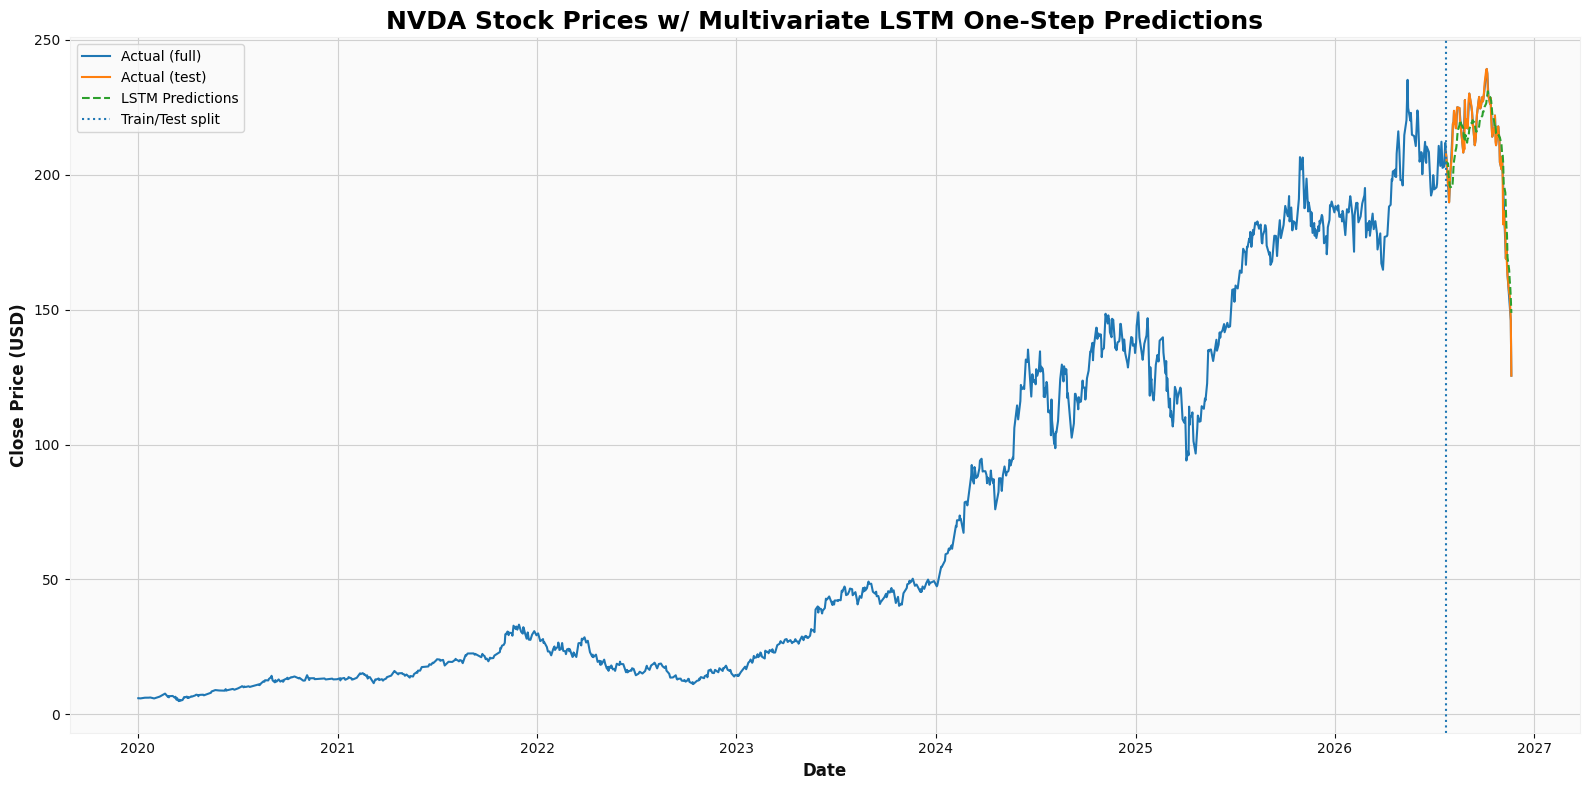

In [16]:
plt.figure(figsize=(16, 8))
plt.plot(prediction_data["Date"], prediction_data["Close"], label="Actual (full)")
plt.plot(lstm_test_dates, y_test.flatten(), label="Actual (test)")
plt.plot(lstm_test_dates, predicts.flatten(), label="LSTM Predictions", linestyle="--")

plt.axvline(x=prediction_data["Date"].values[training_set], linestyle=":", linewidth=1.5, label="Train/Test split")
plt.xlabel("Date", fontsize=12, fontweight="bold")
plt.ylabel("Close Price (USD)", fontsize=12, fontweight="bold")
plt.title(f"{desired_company} Stock Prices w/ Multivariate LSTM One-Step Predictions", fontsize=18, fontweight="bold")

plt.legend()
plt.tight_layout()
plt.show()

---
## <u>XGBoost Model</u>

XGBoost is a machine learning model based on gradient-boosted decision trees. It builds many small decision trees one after another, where each new tree attempts to improve on the errors made by the previous trees. Instead of learning from raw sequences, XGBoost learns relationships from structured input features. It is especially effective when the data has many engineered variables that describe trends, patterns, and relationships.

In this project, XGBoost is used to predict the stock’s next-day return rather than the next closing price directly. The model is trained on engineered features such as lagged returns, moving-average relationships, volatility, momentum, RSI, MACD, volume-based features, calendar variables, and broader market returns from SPY and QQQ. After XGBoost predicts the next-day return, that return is converted into a predicted closing price so the model can be evaluated alongside the LSTM and N-BEATS forecasts.

---
##### **Feature Engineering**

In [17]:
xgb_df = prediction_data[["Date", "Open", "High", "Low", "Close", "Volume"]].copy()
xgb_df = xgb_df.sort_values("Date").reset_index(drop=True)

# Basic daily movement features
xgb_df["Return_1d"] = xgb_df["Close"].pct_change(fill_method=None)
xgb_df["Open_Close_Return"] = (xgb_df["Close"] - xgb_df["Open"]) / xgb_df["Open"]
xgb_df["High_Low_Range"] = (xgb_df["High"] - xgb_df["Low"]) / xgb_df["Close"]

# Store lagged returns to give XGBoost a tabular version of recent price history
for lag in range(0, LOOKBACK):
    xgb_df[f"Return_lag_{lag}"] = xgb_df["Return_1d"].shift(lag)

# Rolling features summarize trend, volatility, and momentum across several windows
rolling_windows = [5, 10, 20, LOOKBACK]

for window in rolling_windows:
    xgb_df[f"SMA_{window}"] = xgb_df["Close"].rolling(window).mean()
    xgb_df[f"Close_to_SMA_{window}"] = (xgb_df["Close"] / xgb_df[f"SMA_{window}"]) - 1
    xgb_df[f"Volatility_{window}"] = xgb_df["Return_1d"].rolling(window).std()
    xgb_df[f"Momentum_{window}"] = xgb_df["Close"].pct_change(window, fill_method=None)

# Volume features capture trading activity
xgb_df["Volume_Change"] = xgb_df["Volume"].pct_change(fill_method=None)

for window in [5, 20]:
    xgb_df[f"Volume_SMA_{window}"] = xgb_df["Volume"].rolling(window).mean()
    xgb_df[f"Volume_to_SMA_{window}"] = xgb_df["Volume"] / xgb_df[f"Volume_SMA_{window}"]

# RSI - indicator of recent upward or downward trends
delta = xgb_df["Close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(14).mean()
avg_loss = loss.rolling(14).mean()

rs = avg_gain / avg_loss
xgb_df["RSI_14"] = 100 - (100 / (1 + rs))

# Moving Average Convergence Divergence (MACD) features are technical indicators that try to capture trend and momentum by comparing a short-term moving average to a longer-term moving average
xgb_df["EMA_12"] = xgb_df["Close"].ewm(span=12, adjust=False).mean()
xgb_df["EMA_26"] = xgb_df["Close"].ewm(span=26, adjust=False).mean()
xgb_df["MACD"] = xgb_df["EMA_12"] - xgb_df["EMA_26"]
xgb_df["MACD_Signal"] = xgb_df["MACD"].ewm(span=9, adjust=False).mean()
xgb_df["MACD_Hist"] = xgb_df["MACD"] - xgb_df["MACD_Signal"]

# Calendar features
xgb_df["DayOfWeek"] = pd.to_datetime(xgb_df["Date"]).dt.dayofweek
xgb_df["Month"] = pd.to_datetime(xgb_df["Date"]).dt.month

# Market context: SPY and QQQ returns
market_df = data[data["Ticker"].isin(["SPY", "QQQ"])][["Date", "Ticker", "Close"]].copy()
market_df = market_df.pivot(index="Date", columns="Ticker", values="Close").reset_index()

market_df["SPY_Return_1d"] = market_df["SPY"].pct_change(fill_method=None)
market_df["QQQ_Return_1d"] = market_df["QQQ"].pct_change(fill_method=None)
market_df["SPY_Return_5d"] = market_df["SPY"].pct_change(5, fill_method=None)
market_df["QQQ_Return_5d"] = market_df["QQQ"].pct_change(5, fill_method=None)

market_features = ["Date", "SPY_Return_1d", "QQQ_Return_1d", "SPY_Return_5d", "QQQ_Return_5d"]

xgb_df = xgb_df.merge(market_df[market_features], on="Date", how="left")

xgb_df["Target_Close"] = xgb_df["Close"].shift(-1) #  stock closing price for the following day
xgb_df["Target_Return_1d"] = (xgb_df["Target_Close"] / xgb_df["Close"]) - 1 # stock percent return for the following day, which is what XGBoost learns to predict
xgb_df["Target_Date"] = xgb_df["Date"].shift(-1)
xgb_df["Target_Index"] = xgb_df.index + 1

xgb_df = xgb_df.replace([np.inf, -np.inf], np.nan).dropna().copy()

# Features to use
feature_cols = [
    "Close",
    "Open_Close_Return",
    "High_Low_Range",
    "Volume_Change",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "DayOfWeek",
    "Month",
    "SPY_Return_1d",
    "QQQ_Return_1d",
    "SPY_Return_5d",
    "QQQ_Return_5d",
]

# Add all lagged return features
feature_cols += [f"Return_lag_{lag}" for lag in range(0, LOOKBACK)]

# Add rolling features
for window in rolling_windows:
    feature_cols += [
        f"Close_to_SMA_{window}",
        f"Volatility_{window}",
        f"Momentum_{window}",
    ]

# Add volume-ratio features
feature_cols += ["Volume_to_SMA_5", "Volume_to_SMA_20"]

# Train/test split based on the target day, not the feature day
xgb_train_df = xgb_df[xgb_df["Target_Index"] < training_set].copy()
xgb_test_df = xgb_df[xgb_df["Target_Index"] >= training_set].copy()

# Build input matrix and target vector for XGBoost
X_train_xgb = xgb_train_df[feature_cols].values
y_train_xgb = xgb_train_df["Target_Return_1d"].values

X_test_xgb = xgb_test_df[feature_cols].values

print(f"XGBoost train samples : {X_train_xgb.shape[0]}")
print(f"XGBoost test samples  : {X_test_xgb.shape[0]}")
print(f"Features per sample   : {X_train_xgb.shape[1]}")
print(f"Look-back window      : {LOOKBACK} days")
if len(X_train_xgb) == 0 or len(X_test_xgb) == 0:
    raise ValueError('XGBoost has no valid samples after feature preparation.')

XGBoost train samples : 1615
XGBoost test samples  : 86
Features per sample   : 58
Look-back window      : 30 days


---
##### **Model Definition & Training**

In [18]:
# Define the XGBoost model
xgb_model = xgb.XGBRegressor(
    n_estimators=800,               # number of boosted decision trees
    max_depth=3,                    # shallow trees reduce overfitting
    learning_rate=0.02,             # small learning rate makes update more gradual
    subsample=0.85,                 # each tree trains on 85% of rows
    colsample_bytree=0.85,          # each tree trains on 85% of features
    min_child_weight=5,             # discourages overly specific splits
    reg_alpha=0.1,                  # L1 regularization, which penalizes complex models
    reg_lambda=2.0,                 # L2 regularization, which discourages overreacting to patterns
    objective="reg:squarederror",   # identifies the problem the model is designed to solve, which is a regression task using squared error loss
    random_state=42,                # reproducibility
    n_jobs=-1,                      # number of CPU cores used
    verbosity=0,
)

xgb_model.fit(X_train_xgb, y_train_xgb, verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.85, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.02, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=800,
             n_jobs=-1, num_parallel_tree=None, ...)

---
##### **Performance Metrics**

In [19]:
# XGBoost predicts the next-day return.
# Predicted next close = today's close * (1 + predicted return)

xgb_pred_returns = xgb_model.predict(X_test_xgb)

xgb_current_close = xgb_test_df["Close"].values
xgb_preds = xgb_current_close * (1 + xgb_pred_returns) # convert predicted return into predicted close

# Actual tomorrow close and dates for  testing
y_test_xgb_inv = xgb_test_df["Target_Close"].values
xgb_test_dates = xgb_test_df["Target_Date"].values

xgb_mse  = mean_squared_error(y_test_xgb_inv, xgb_preds)
xgb_rmse = np.sqrt(xgb_mse)
xgb_mae  = np.mean(np.abs(xgb_preds - y_test_xgb_inv))
xgb_mape = np.mean(np.abs((xgb_preds - y_test_xgb_inv) / y_test_xgb_inv)) * 100

actual_direction = np.sign(y_test_xgb_inv - xgb_current_close)
predicted_direction = np.sign(xgb_preds - xgb_current_close)
xgb_directional_accuracy = np.mean(actual_direction == predicted_direction) * 100

print(f"XGBoost MSE : {xgb_mse:.4f}")
print(f"XGBoost RMSE: {xgb_rmse:.4f}")
print(f"XGBoost MAE : {xgb_mae:.4f}")
print(f"XGBoost MAPE: {xgb_mape:.2f}%")
print(f"XGBoost Directional Accuracy: {xgb_directional_accuracy: .2f}%")

XGBoost MSE : 44.4544
XGBoost RMSE: 6.6674
XGBoost MAE : 4.9091
XGBoost MAPE: 2.52%
XGBoost Directional Accuracy:  46.51%


---
##### **Visualization**

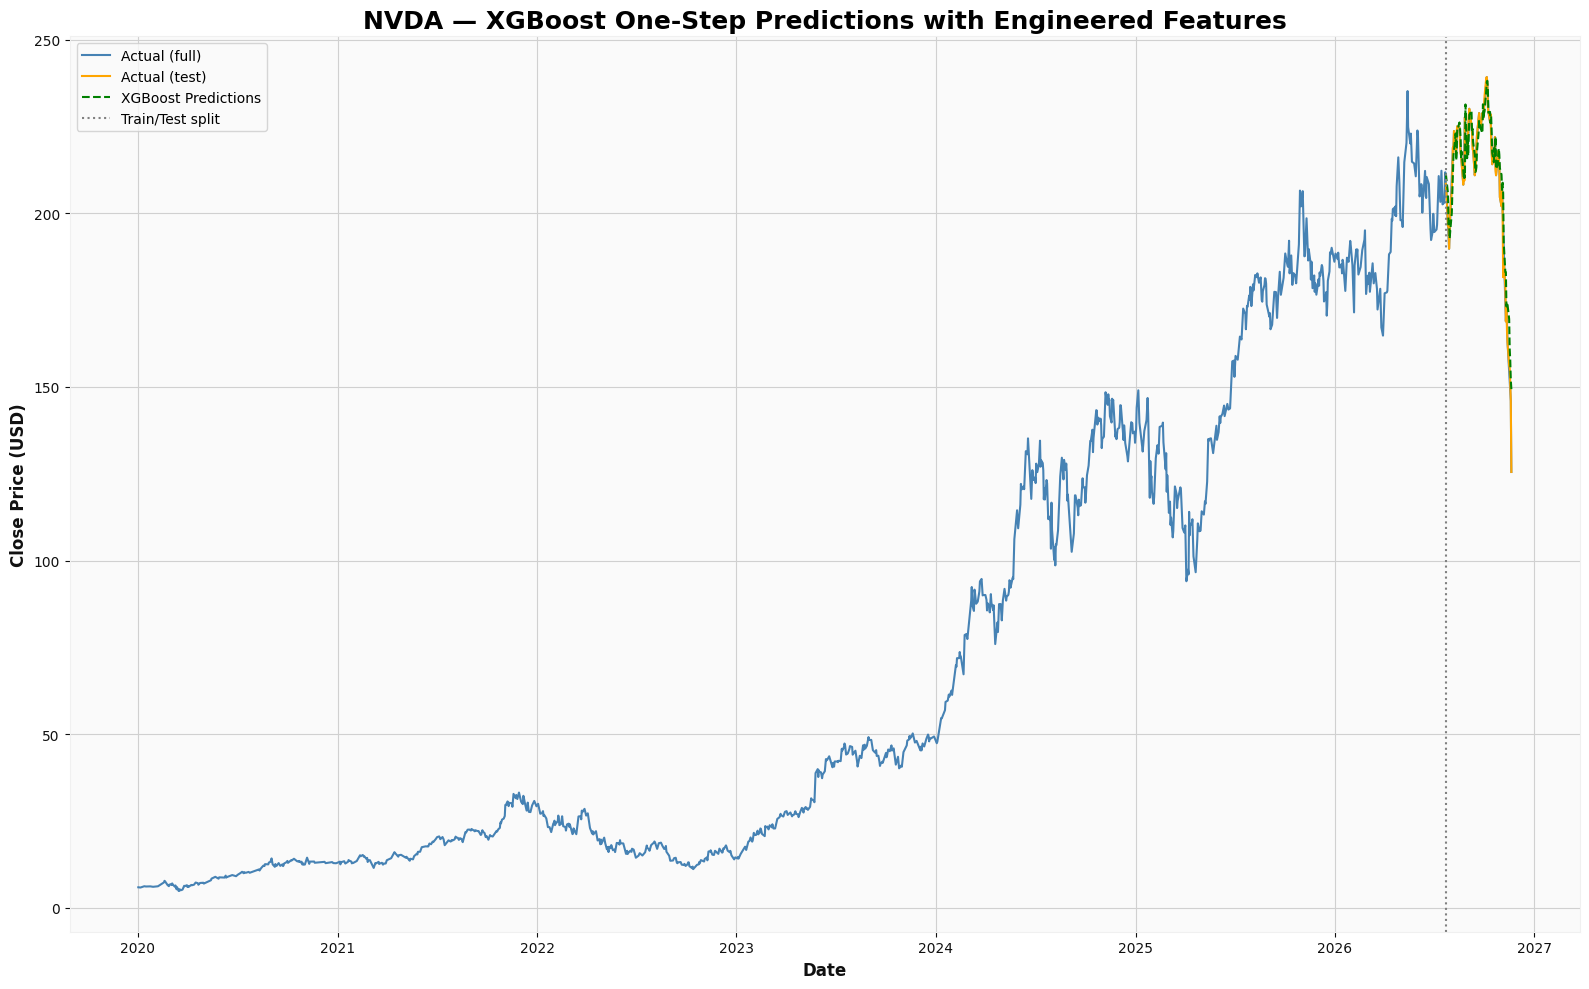

In [20]:
xgb_train_end = prediction_data["Date"].values[training_set]

plt.figure(figsize=(16, 10))
plt.plot(prediction_data["Date"], prediction_data["Close"], label="Actual (full)", color="steelblue")
plt.plot(xgb_test_dates, y_test_xgb_inv, label="Actual (test)", color="orange")
plt.plot(xgb_test_dates, xgb_preds, label="XGBoost Predictions", color="green", linestyle="--")

plt.axvline(x=xgb_train_end, color="grey", linestyle=":", linewidth=1.5, label="Train/Test split")
plt.xlabel("Date", fontsize=12, fontweight="bold")
plt.ylabel("Close Price (USD)", fontsize=12, fontweight="bold")
plt.title(f"{desired_company} — XGBoost One-Step Predictions with Engineered Features", fontsize=18, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

---
##### **Feature Importance**

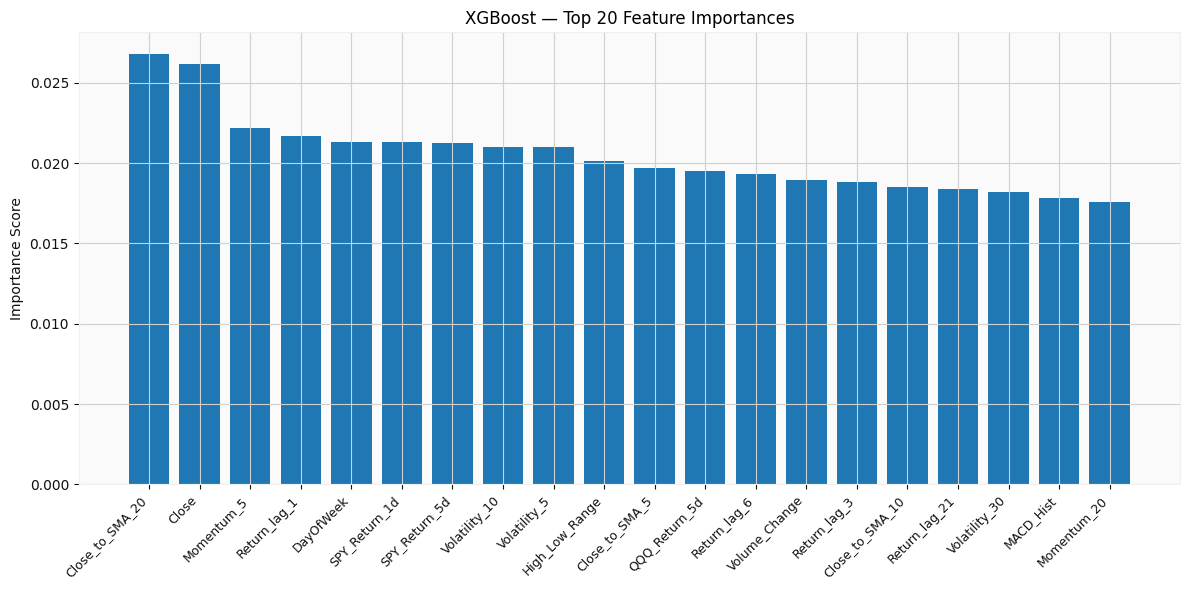

In [21]:
importances = xgb_model.feature_importances_

top_n = 20
top_idx = np.argsort(importances)[-top_n:][::-1]

plt.figure(figsize=(12, 6))
plt.bar(range(top_n), importances[top_idx])
plt.xticks(range(top_n), [feature_cols[i] for i in top_idx], rotation=45, ha="right", fontsize=9)
plt.ylabel("Importance Score")
plt.title("XGBoost — Top 20 Feature Importances")
plt.tight_layout()
plt.show()

---
## <u>N-BEATS Model</u>

N-BEATS is a neural network architecture designed specifically for time-series forecasting. It uses fully connected layers arranged in blocks that learn patterns from historical values and generate a forecast. Rather than using recurrence, the model learns from fixed windows of past observations and updates its internal weights during training to reduce forecasting error. Its structure allows it to model time-series behavior directly from historical data.

In this project, N-BEATS is used as a univariate forecasting model, meaning it only uses the stock’s historical closing prices as input. The model receives the previous 30 trading days of closing prices and predicts the next closing price. This allows the project to test how well a sequence-based neural forecasting model performs using only the stock’s own price history, without additional technical indicators or market-context features.

---
##### **Data Preparation**

In [22]:
# N-BEATS is used as a univariate sequence model that only receives historical closing prices as input.

# Scale close prices using only the training set to avoid leakage.
nbeats_scaler = MinMaxScaler(feature_range=(0, 1))
nbeats_scaler.fit(dataset[:training_set].reshape(-1, 1))
nbeats_scaled = nbeats_scaler.transform(dataset.reshape(-1, 1)).flatten()

def build_sequence_windows(series, first_target_idx, last_target_exclusive, lookback=LOOKBACK):
    """Build sequence windows where each target is the next day after the window.

    Each X window contains the prior lookback values.
    Each y target is the next value immediately after that window.
    """
    x, y = [], []
    for i in range(first_target_idx, last_target_exclusive):
        x.append(series[i - lookback: i])
        y.append(series[i])
    return np.array(x, dtype=np.float32), np.array(y, dtype=np.float32).reshape(-1, 1)

# Training windows predict training-period target days
x_train_nbeats, y_train_nbeats = build_sequence_windows(
    nbeats_scaled,
    first_target_idx=LOOKBACK,
    last_target_exclusive=training_set,
)

# Test windows use real prior prices to predict test days
X_test_nbeats, y_test_nbeats_scaled = build_sequence_windows(
    nbeats_scaled,
    first_target_idx=training_set,
    last_target_exclusive=len(nbeats_scaled),
)

print(f"N-BEATS train samples: {x_train_nbeats.shape[0]}")
print(f"N-BEATS test samples : {X_test_nbeats.shape[0]}")
print(f"Look-back window     : {LOOKBACK} days")

N-BEATS train samples: 1616
N-BEATS test samples : 86
Look-back window     : 30 days


---
##### **Model Definition & Training**

In [23]:
torch.manual_seed(42)
torch.set_num_threads(1)  # reduces CPU overhead for this small training loop

device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # use GPU if available, otherwise use CPU

# Convert NumPy arrays into PyTorch tensors, which is PyTorch's version of an array used for neural network training
train_ds = TensorDataset(
    torch.tensor(x_train_nbeats, dtype=torch.float32),
    torch.tensor(y_train_nbeats, dtype=torch.float32),
)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

# Define the N-BEATS model
nbeats_model = NBeatsNet(
    device=device,                  # selects hardware to run model
    stack_types=(                   # assign each stack a general block to learn patterns from closing prices
        NBeatsNet.GENERIC_BLOCK,
        NBeatsNet.GENERIC_BLOCK
        ),
    nb_blocks_per_stack=2,          # assign 2 blocks per stack
    forecast_length=1,              # one-step-ahead forecast
    backcast_length=LOOKBACK,       # 30 real prior days
    thetas_dim=(8, 8),              # learning capacity
    share_weights_in_stack=False,   # each block holds its own weights
    hidden_layer_units=64,
).to(device)

# Adam updates the model weights
optimizer = torch.optim.Adam(nbeats_model.parameters(), lr=1e-3)
loss_fn = torch.nn.MSELoss()
# NBEATS_EPOCHS is configured in Experiment settings.

nbeats_model.train()
for epoch in range(1, NBEATS_EPOCHS + 1):
    epoch_losses = []
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        _, forecast = nbeats_model(batch_x)
        loss = loss_fn(forecast, batch_y)
        loss.backward()
        optimizer.step()
        epoch_losses.append(loss.item())

    if epoch == 1 or epoch % 10 == 0 or epoch == NBEATS_EPOCHS:
        print(f"Epoch {epoch:03d}/{NBEATS_EPOCHS} - loss: {np.mean(epoch_losses):.6f}")

| N-Beats
| --  Stack Generic (#0) (share_weights_in_stack=False)
     | -- GenericBlock(units=64, thetas_dim=8, backcast_length=30, forecast_length=1, share_thetas=False) at @138260383906992
     | -- GenericBlock(units=64, thetas_dim=8, backcast_length=30, forecast_length=1, share_thetas=False) at @138259802787344
| --  Stack Generic (#1) (share_weights_in_stack=False)
     | -- GenericBlock(units=64, thetas_dim=8, backcast_length=30, forecast_length=1, share_thetas=False) at @138259802787664
     | -- GenericBlock(units=64, thetas_dim=8, backcast_length=30, forecast_length=1, share_thetas=False) at @138260395756592
Epoch 001/50 - loss: 0.049048
Epoch 010/50 - loss: 0.000484
Epoch 020/50 - loss: 0.000359
Epoch 030/50 - loss: 0.000438
Epoch 040/50 - loss: 0.000413
Epoch 050/50 - loss: 0.000312


---
##### **Performance Metrics**

In [24]:
nbeats_model.eval() # evaluation mode for model

# Generate predictions without tracking gradients
with torch.no_grad():
    test_tensor = torch.tensor(X_test_nbeats, dtype=torch.float32).to(device)
    _, nbeats_preds_scaled_tensor = nbeats_model(test_tensor)

# Convert PyTorch tensor outputs back into NumPy
nbeats_preds_scaled = nbeats_preds_scaled_tensor.cpu().numpy()

# Convert scaled predictions back into dollar closing prices
nbeats_preds = nbeats_scaler.inverse_transform(nbeats_preds_scaled).flatten()

nbeats_actual = prediction_data["Close"].values[training_set:]

nbeats_mse  = mean_squared_error(nbeats_actual, nbeats_preds)
nbeats_rmse = np.sqrt(nbeats_mse)
nbeats_mae  = np.mean(np.abs(nbeats_preds - nbeats_actual))
nbeats_mape = np.mean(np.abs((nbeats_preds - nbeats_actual) / nbeats_actual)) * 100

nbeats_current_close = prediction_data["Close"].values[training_set - 1 : len(prediction_data) - 1]
actual_direction = np.sign(nbeats_actual - nbeats_current_close)
predicted_direction = np.sign(nbeats_preds - nbeats_current_close)
nbeats_directional_accuracy = np.mean(actual_direction == predicted_direction) * 100

print(f"N-BEATS MSE : {nbeats_mse:.4f}")
print(f"N-BEATS RMSE: {nbeats_rmse:.4f}")
print(f"N-BEATS MAE : {nbeats_mae:.4f}")
print(f"N-BEATS MAPE: {nbeats_mape:.2f}%")
print(f"N-BEATS Directional Accuracy: {nbeats_directional_accuracy: .2f}%")

N-BEATS MSE : 94.7642
N-BEATS RMSE: 9.7347
N-BEATS MAE : 7.3271
N-BEATS MAPE: 3.87%
N-BEATS Directional Accuracy:  40.70%


---
##### **Visualization**

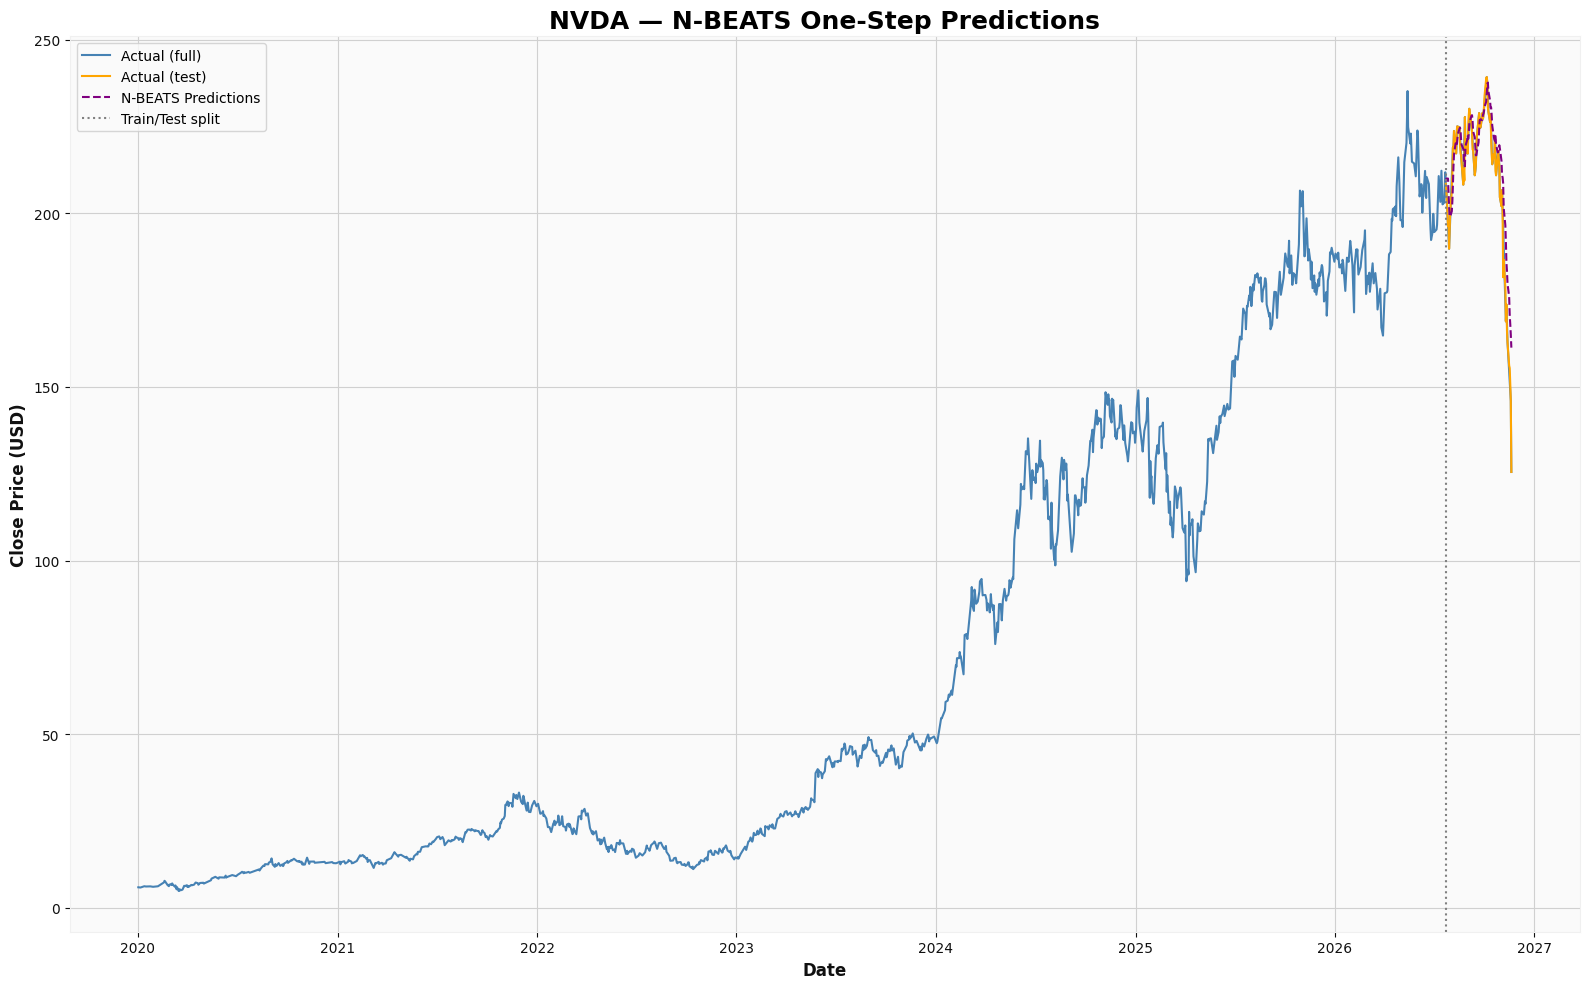

In [25]:
nbeats_test_dates = prediction_data["Date"].values[training_set:]

plt.figure(figsize=(16, 10))
plt.plot(prediction_data["Date"], prediction_data["Close"], label="Actual (full)", color="steelblue")
plt.plot(nbeats_test_dates, nbeats_actual, label="Actual (test)", color="orange")
plt.plot(nbeats_test_dates, nbeats_preds, label="N-BEATS Predictions", color="purple", linestyle="--")

plt.axvline(x=nbeats_test_dates[0], color="grey", linestyle=":", linewidth=1.5, label="Train/Test split")
plt.xlabel("Date", fontsize=12, fontweight="bold")
plt.ylabel("Close Price (USD)", fontsize=12, fontweight="bold")
plt.title(f"{desired_company} — N-BEATS One-Step Predictions", fontsize=18, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()


---
## <u>Model Comparison</u>

The final comparison evaluates each model as a forecasting pipeline for the same one-step-ahead closing price prediction task:

- **LSTM:** multivariate 30-day sequence of engineered daily features.
- **XGBoost:** engineered tabular features.
- **N-BEATS:** univariate close-price sequence.

---
##### **Metrics Table**

In [26]:
# Verify comparable dates before presenting the combined comparison.
expected_dates = pd.DatetimeIndex(prediction_data['Date'].values[training_set:])
for name, dates in [('LSTM', lstm_test_dates), ('XGBoost', xgb_test_dates),
                    ('N-BEATS', nbeats_test_dates)]:
    if not pd.DatetimeIndex(dates).equals(expected_dates):
        raise ValueError(f'{name} target dates differ from the shared test period. '
                         'Check missing data before comparing model metrics.')
for values in [predicts, xgb_preds, nbeats_preds]:
    if not np.isfinite(values).all():
        raise ValueError('A model produced non-finite predictions.')
print(f'All three models cover the same {len(expected_dates)} test observations.')

All three models cover the same 86 test observations.


In [27]:
# All three models use the same one-step-ahead protocol and the same train/test split.
comparison = pd.DataFrame({
    "Model" : ["LSTM",    "XGBoost",  "N-BEATS"],
    "Input Strategy": [
        "Multivariate sequence",
        "Engineered tabular features",
        "Univariate sequence",
    ],
    "RMSE"  : [rmse,      xgb_rmse,   nbeats_rmse],
    "MAE"   : [lstm_mae,  xgb_mae,    nbeats_mae],
    "MAPE%" : [lstm_mape, xgb_mape,   nbeats_mape],
    "Directional Accuracy%": [lstm_directional_accuracy, xgb_directional_accuracy, nbeats_directional_accuracy]
})
comparison = comparison.set_index("Model")
print(comparison.round(4).to_string())

                      Input Strategy    RMSE     MAE   MAPE%  Directional Accuracy%
Model                                                                              
LSTM           Multivariate sequence  8.8847  7.2337  3.5862                46.5116
XGBoost  Engineered tabular features  6.6674  4.9091  2.5222                46.5116
N-BEATS          Univariate sequence  9.7347  7.3271  3.8729                40.6977


---
##### **Model Performance Comparison**

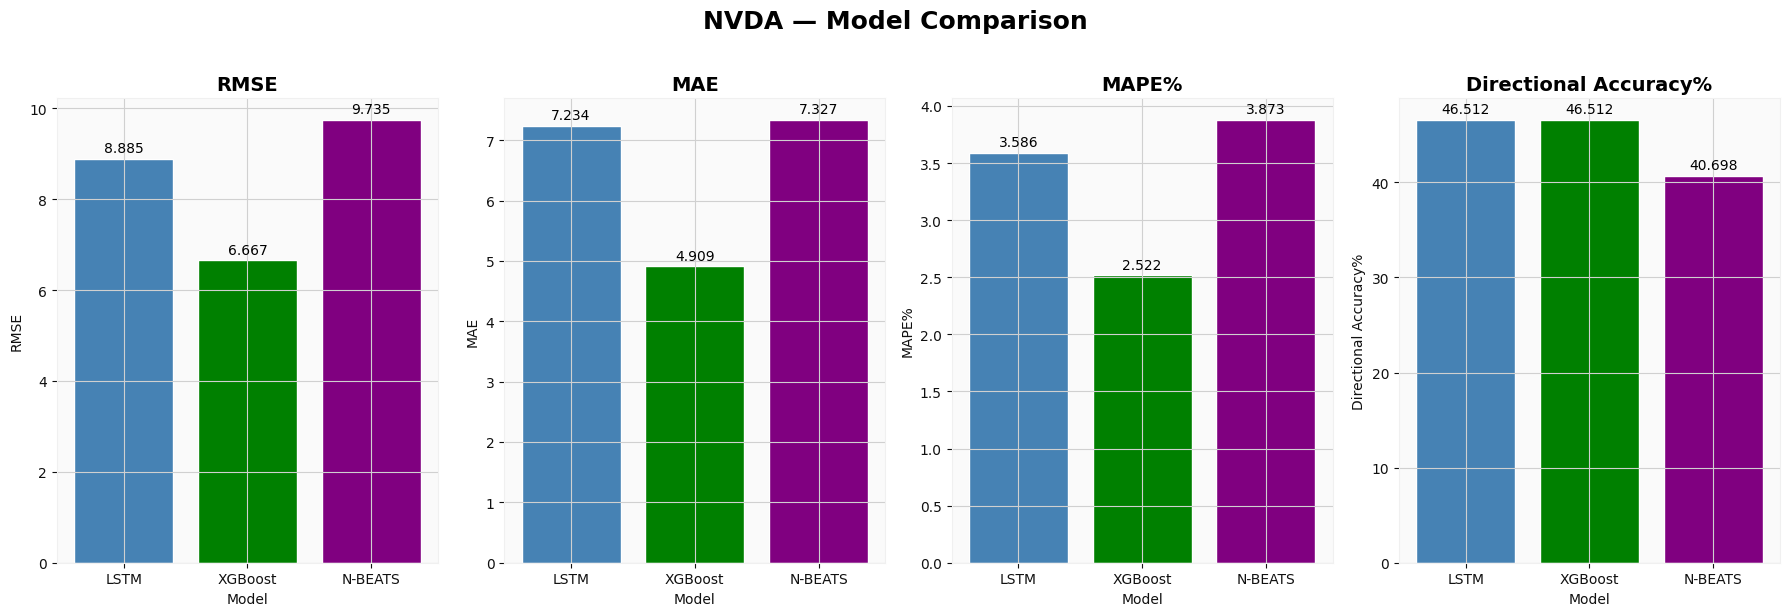

In [28]:
# Compare performance metrics for each model
metrics = ["RMSE", "MAE", "MAPE%", "Directional Accuracy%"]
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

colors = ["steelblue", "green", "purple"]
for ax, metric in zip(axes, metrics):
    bars = ax.bar(comparison.index, comparison[metric], color=colors, edgecolor="white")
    ax.set_title(metric, fontsize=14, fontweight="bold")
    ax.set_ylabel(metric)
    ax.set_xlabel("Model")
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() * 1.01,
            f"{bar.get_height():.3f}",
            ha="center", va="bottom", fontsize=10,
        )

plt.suptitle(f"{desired_company} — Model Comparison", fontsize=18, fontweight="bold", y=1.02)
plt.tight_layout()
comparison_metrics_figure = fig
plt.show()


---
##### **Predicted Prices Comparison**

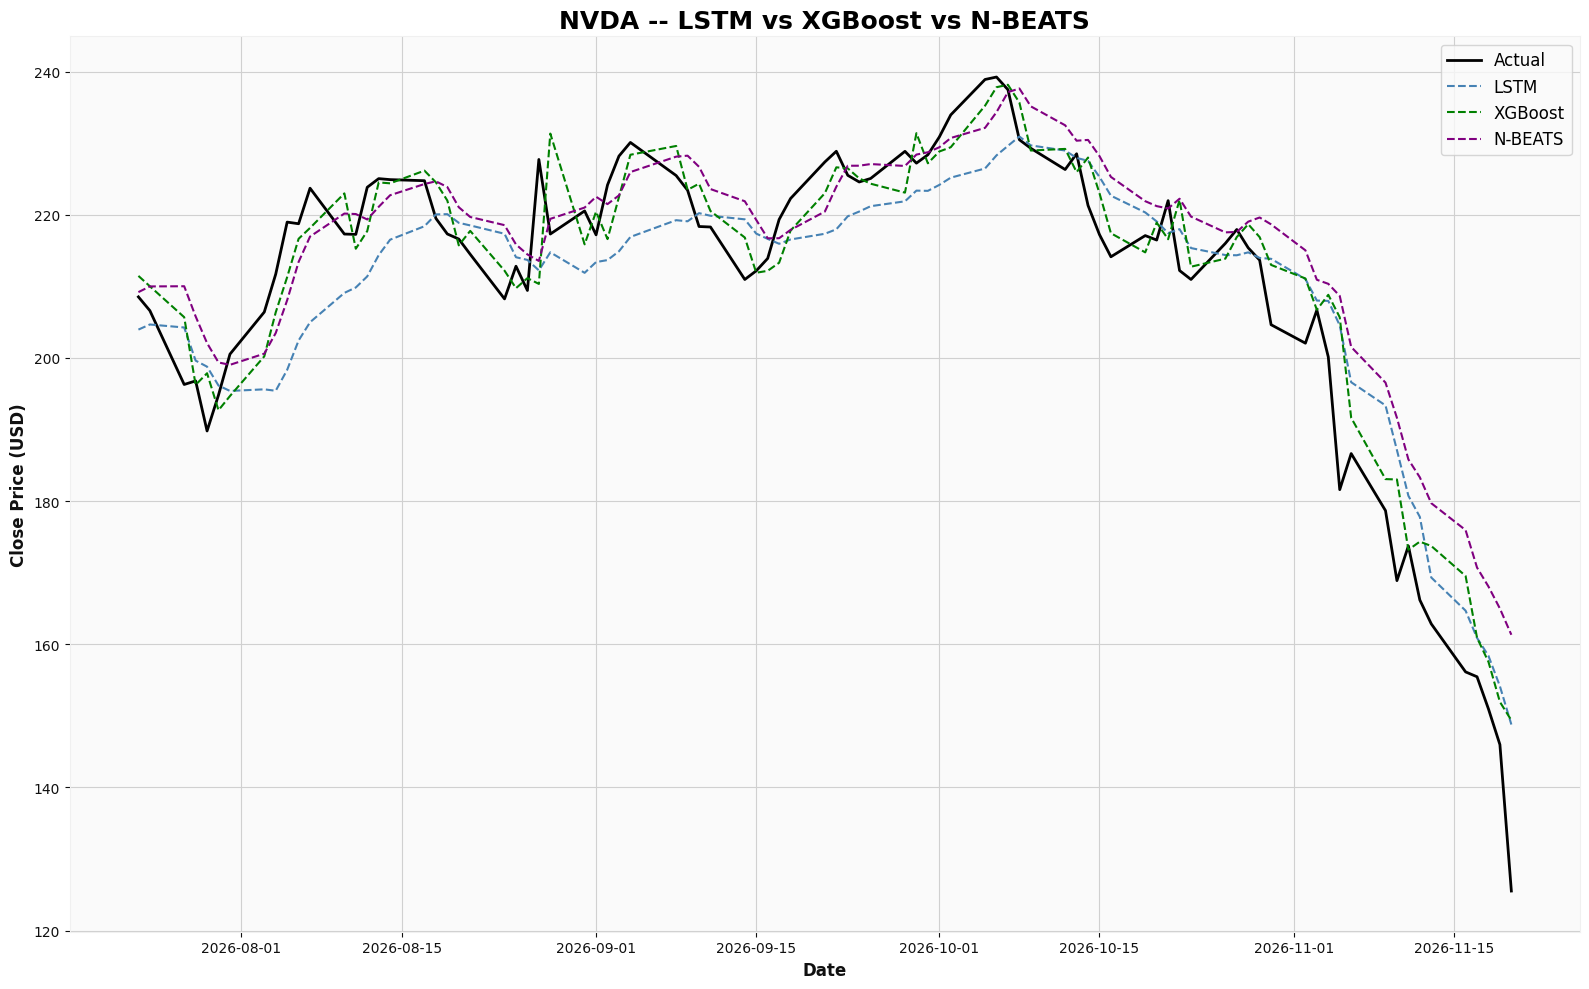

In [29]:
# Visualize closing price predictions for each model against the actual closing prices during the testing period
plt.figure(figsize=(16, 10))

plt.plot(lstm_test_dates, y_test.flatten(), label="Actual", color="black", linewidth=2)
plt.plot(lstm_test_dates, predicts.flatten(), label="LSTM", color="steelblue", linestyle="--")
plt.plot(xgb_test_dates, xgb_preds, label="XGBoost", color="green", linestyle="--")
plt.plot(nbeats_test_dates, nbeats_preds, label="N-BEATS", color="purple", linestyle="--")

plt.xlabel("Date", fontsize=12, fontweight="bold")
plt.ylabel("Close Price (USD)", fontsize=12, fontweight="bold")
plt.title(f"{desired_company} -- LSTM vs XGBoost vs N-BEATS", fontsize=18, fontweight="bold")
plt.legend(fontsize=12)
plt.tight_layout()
comparison_prices_figure = plt.gcf()
plt.show()

## Save results for the report

Exports the downloaded data, model metrics, aligned predictions, graphs, and run settings. Colab storage is temporary: download the ZIP before the runtime ends.

In [30]:
SOURCE_NOTEBOOK_SHA256 = "de171f869a8abf620e44b67214d011ae2bf5b4c75112b1a31a982fc42c377485"
import shutil
comparison.to_csv(OUTPUT_DIR / 'model_metrics.csv')
predictions = pd.DataFrame({
    'Date': pd.to_datetime(lstm_test_dates),
    'Actual': y_test.flatten(),
    'PreviousClose': lstm_current_close,
    'LSTM': predicts.flatten(), 'XGBoost': np.asarray(xgb_preds).flatten(),
    'N-BEATS': np.asarray(nbeats_preds).flatten(),
})
predictions.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
packages = ['numpy', 'pandas', 'tensorflow', 'torch', 'scikit-learn', 'curl_cffi',
            'xgboost', 'yfinance', 'mplfinance', 'nbeats-pytorch']
manifest = {
    'source_notebook_sha256': SOURCE_NOTEBOOK_SHA256,
    'run_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(),
    'packages': {name: version(name) for name in packages},
    'ticker': desired_company, 'start_year': start_year, 'end_year': end_year,
    'actual_first_date': str(prediction_data.Date.min()),
    'actual_last_date': str(prediction_data.Date.max()),
    'raw_rows': len(prediction_data), 'train_boundary': training_set,
    'test_rows': len(predictions), 'lookback': LOOKBACK,
    'lstm_max_epochs': LSTM_EPOCHS, 'lstm_completed_epochs': len(history.epoch),
    'nbeats_epochs': NBEATS_EPOCHS, 'auto_adjust': True, 'random_seed': 42,
}
(OUTPUT_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
# Save the comparison figures produced by the original plotting cells.
comparison_metrics_figure.savefig(OUTPUT_DIR / 'metrics.png', dpi=160, bbox_inches='tight')
comparison_prices_figure.savefig(OUTPUT_DIR / 'predictions.png', dpi=160, bbox_inches='tight')
archive = shutil.make_archive(str(OUTPUT_DIR.parent / 'results'), 'zip', OUTPUT_DIR)
print('Results saved:', archive)
display(comparison.round(4))

Results saved: /content/results.zip


,Input Strategy,RMSE,MAE,MAPE%,Directional Accuracy%
Model,,,,,
LSTM,Multivariate sequence,8.8847,7.2337,3.5862,46.5116
XGBoost,Engineered tabular features,6.6674,4.9091,2.5222,46.5116
N-BEATS,Univariate sequence,9.7347,7.3271,3.8729,40.6977


In [33]:
from sklearn.metrics import r2_score

r2_results = pd.DataFrame({
    "Model": ["LSTM", "XGBoost", "N-BEATS"],
    "R² score": [
        r2_score(np.asarray(y_test).ravel(),
                 np.asarray(predicts).ravel()),

        r2_score(np.asarray(y_test_xgb_inv).ravel(),
                 np.asarray(xgb_preds).ravel()),

        r2_score(np.asarray(nbeats_actual).ravel(),
                 np.asarray(nbeats_preds).ravel()),
    ]
}).set_index("Model")

display(r2_results.round(4))

,R² score
Model,
LSTM,0.8419
XGBoost,0.9110
N-BEATS,0.8102


### Optional browser download
Run this last cell manually if you want Colab to start a browser download. It is disabled by default so Run all is uninterrupted.

In [31]:
DOWNLOAD_ZIP = False #@param {type:"boolean"}
if DOWNLOAD_ZIP:
    try:
        from google.colab import files
    except ImportError:
        print('Outside Colab: the ZIP is available at', archive)
    else:
        files.download(archive)